## Model Experiment

In [1]:

import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Support running from either notebooks/ or the project root
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root))

from src.preprocessing import create_preprocessor, create_smote_pipeline
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score
)

In [3]:
pipeline = Pipeline(
    [
        ("preprocessing",create_preprocessor()),
        ("model",LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state = 42
        ))
    ]
)

In [4]:
train = pd.read_csv("../data/processed/train.csv")

X_train = train.drop(columns = ["Class"])
y_train = train["Class"]

In [5]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [6]:
scaler = StandardScaler()
val = pd.read_csv("../data/processed/val.csv")
X_val = val.drop(columns = ["Class"])
X_val_scaled = scaler.fit_transform(X_val)
y_val = val["Class"]

In [7]:
validation = pipeline.predict(X_val)

In [8]:
# evaluation of random forest model

accuracy_logistic = accuracy_score(
    y_val,
    validation
)

precision_logistic = precision_score(
    y_val,
    validation
)


recall_logistic = recall_score(
    y_val,
    validation
)

f1_logistic = f1_score(
    y_val,
    validation
)

print("Random Forest Evaluation")

print("RF accuracy: ", round(accuracy_logistic,4))
print("RF Precision: ", round(precision_logistic,4))
print("RF recall: ", round(recall_logistic,4))
print("RF F1: ", round(f1_logistic,4))

Random Forest Evaluation
RF accuracy:  0.9744
RF Precision:  0.0549
RF recall:  0.913
RF F1:  0.1036


In [9]:
print("Classification Report")
print("\n ", classification_report(y_val, validation))

Classification Report

                precision    recall  f1-score   support

           0       1.00      0.97      0.99     56653
           1       0.05      0.91      0.10        92

    accuracy                           0.97     56745
   macro avg       0.53      0.94      0.55     56745
weighted avg       1.00      0.97      0.99     56745



Confusion Matrix

 [[55208  1445]
 [    8    84]]


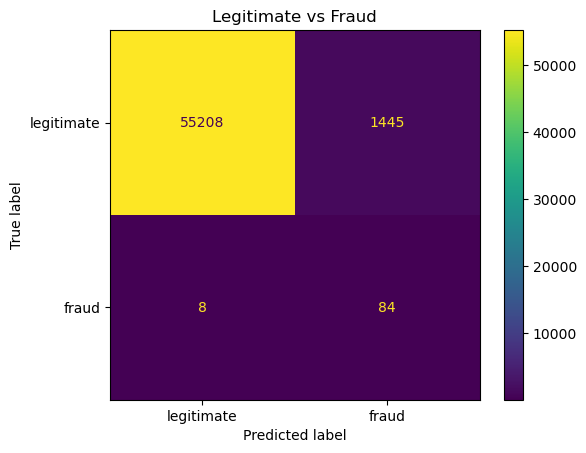

In [10]:
cm = confusion_matrix(y_val, validation)
print("Confusion Matrix")
print("\n", cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels=["legitimate", "fraud"]
)

disp.plot()
plt.title("Legitimate vs Fraud")
plt.show()

## Logistic regression + SMOTE

In [11]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [12]:
smote = SMOTE(random_state=42)

In [13]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [14]:
print("Before SMOTE: ")
print(y_train.value_counts())

print("After SMOTE: ")
print(y_train_smote.value_counts())

Before SMOTE: 
Class
0    169944
1       291
Name: count, dtype: int64
After SMOTE: 
Class
0    169944
1    169944
Name: count, dtype: int64


In [15]:
# logistic_smote = LogisticRegression(
#     max_iter=1000,
#     random_state=42
# )

# X_train_smote_scaled = scaler.fit_transform(X_train_smote)
# logistic_smote.fit(
#     X_train_smote_scaled,
#     y_train_smote
# )

# print("Logistic Regression SMOTE Training Complete...")


smote_pipeline = create_smote_pipeline()

smote_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessing', StandardScaler()),
                ('smote', SMOTE(random_state=42)),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [16]:
# SMOTE MODEL PREDICTION
# X_val_scaled = scaler.fit_transform(X_val)
y_pred_smote = smote_pipeline.predict(
    X_val
)

In [17]:
## Evaluation of SMOTE model

accuracy_smote = accuracy_score(
    y_val,
    y_pred_smote
)

precision_smote = precision_score(
    y_val,
    y_pred_smote
)

f1_smote = f1_score(
    y_val,
    y_pred_smote
)

recall_smote = recall_score(
    y_val,
    y_pred_smote
)


print("Accuracy Score: ", round(accuracy_smote,4))
print("Precision Score: ", round(precision_smote,4))
print("Recall Score: ", round(recall_smote,4))
print("F1 Score: ", round(f1_smote,4))

Accuracy Score:  0.9723
Precision Score:  0.0504
Recall Score:  0.9022
F1 Score:  0.0955


In [18]:
print(
    classification_report(
        y_val,
        y_pred_smote
    )
)

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56653
           1       0.05      0.90      0.10        92

    accuracy                           0.97     56745
   macro avg       0.53      0.94      0.54     56745
weighted avg       1.00      0.97      0.98     56745



Confusion Matrix: 
 [[55090  1563]
 [    9    83]]


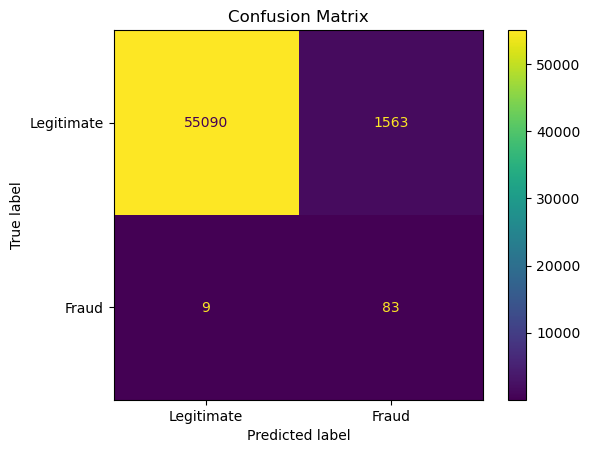

In [19]:
cm_smote = confusion_matrix(y_val, y_pred_smote)

print("Confusion Matrix: \n", cm_smote)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["Legitimate","Fraud"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

## Random Forest Classifier

In [20]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(class_weight='balanced', max_depth=12, n_jobs=-1,
                       random_state=42)

In [21]:
rf_pred = rf_model.predict(
    X_val
)

In [22]:
# evaluation of random forest model

accuracy_rf = accuracy_score(
    y_val,
    rf_pred
)

precision_rf = precision_score(
    y_val,
    rf_pred
)


recall_rf = recall_score(
    y_val,
    rf_pred
)

f1_rf = f1_score(
    y_val,
    rf_pred
)

print("Random Forest Evaluation")

print("RF accuracy: ", round(accuracy_rf,4))
print("RF Precision: ", round(precision_rf,4))
print("RF recall: ", round(recall_rf,4))
print("RF F1: ", round(f1_rf,4))

Random Forest Evaluation
RF accuracy:  0.9995
RF Precision:  0.875
RF recall:  0.837
RF F1:  0.8556


In [23]:
print(classification_report(
    y_val,
    rf_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56653
           1       0.88      0.84      0.86        92

    accuracy                           1.00     56745
   macro avg       0.94      0.92      0.93     56745
weighted avg       1.00      1.00      1.00     56745



[[56642    11]
 [   15    77]]


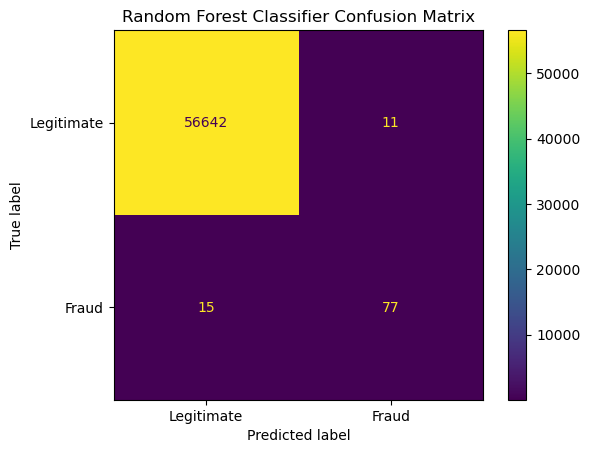

In [24]:
cm_rf = confusion_matrix(
    y_val,
    rf_pred
)

print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Legitimate","Fraud"]
)

disp.plot()
plt.title("Random Forest Classifier Confusion Matrix")
plt.show()

## Final Model Comparison Table

In [25]:
final_report = pd.DataFrame({
    "Model":[
        "Logistic Regression - Balanced",
        "logistic_smote",
        "Random Forest - Balanced"
    ],
    "Accuracy":[
        accuracy_logistic,
        accuracy_smote,
        accuracy_rf
    ],
    "Precision":[
        precision_logistic,
        precision_smote,
        precision_rf
    ],
    "Recall":[
        recall_logistic,
        recall_smote,
        recall_rf
    ],
    "F1_score":[
        f1_logistic,
        f1_smote,
        f1_rf
    ]
})

display(final_report.round(4))

,Model,Accuracy,Precision,Recall,F1_score
0,Logistic Regression - Balanced,0.9744,0.0549,0.9130,0.1036
1,logistic_smote,0.9723,0.0504,0.9022,0.0955
2,Random Forest - Balanced,0.9995,0.8750,0.8370,0.8556
